# Лабораторная работа №2. Логистическая и линейная регрессия

Наборы данных, разбиение и метрики - те же, что в ЛР1 (обоснование выбора - в `LR1_knn.ipynb`):
- классификация отзывов на аниме (3 класса) - **macro-F1**, accuracy;
- регрессия влияния финансовой новости - **MAE**, RMSE, R2.

### Общие функции
Загрузка и разбиение данных, очистка текста, LSA-признаки, метаданные новостей, метрики и сохранение результатов. Эта ячейка одинакова во всех ЛР, чтобы разбиение train/test и метрики совпадали.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score, StratifiedKFold, KFold
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score, f1_score, mean_absolute_error,
                             mean_squared_error, r2_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

ROOT = Path.cwd().parent  # ноутбук запускается из labs/
DATA = ROOT / "data"
RESULTS = Path.cwd() / "results"
CACHE = DATA / "cache"
SEED = 42

# Имена признаков (заполняются при построении признаков) - для графиков важности
FEATURE_NAMES = {}
STAT_NAMES = ["log_len", "log_words", "excl_%", "quest_%", "smile_balance_%"]

CLASSES = ["Отрицательный", "Нейтральный", "Положительный"]


def clean_text(s: str) -> str:
    """Нижний регистр, удаление смайлов вида :lonely:, ссылок и лишних пробелов."""
    s = str(s).lower().replace("ё", "е")
    s = re.sub(r":[a-z_]+:", " ", s)
    s = re.sub(r"https?://\S+", " ", s)
    s = re.sub(r"\s+", " ", s)
    return s.strip()


def load_anime():
    """Отзывы на аниме -> (тексты train, тексты test, y train, y test). y: 0/1/2 = отр/нейтр/пол."""
    df = pd.read_csv(DATA / "anime" / "Anime_reviews_RU.csv", index_col=0).dropna(subset=["Text"])
    y = df["Rate"].map({c: i for i, c in enumerate(CLASSES)}).to_numpy()
    X = df["Text"].map(clean_text).to_numpy()
    return train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)


def load_finnews():
    """Финансовые новости -> (df train, df test, y train, y test).

    Колонка reasoning исключается: это объяснение оценки, сгенерированное вместе с answer,
    т.е. прямая утечка целевой переменной.
    """
    df = pd.read_csv(DATA / "finnews" / "data.csv", index_col=0)
    df["text"] = df["article_text"].map(clean_text)
    y = df["answer"].to_numpy(dtype=float)
    X = df[["text", "sphere", "source", "date"]].reset_index(drop=True)
    return train_test_split(X, y, test_size=0.2, random_state=SEED)


def text_stats(texts) -> np.ndarray:
    """Простые числовые признаки текста: длина, число слов, доля '!', '?', заглавных скобок-смайлов."""
    rows = []
    for t in texts:
        n = max(len(t), 1)
        rows.append([np.log1p(len(t)), np.log1p(len(t.split())), t.count("!") / n * 100,
                     t.count("?") / n * 100, (t.count(")") - t.count("(")) / n * 100])
    return np.array(rows)


def svd_features(train_texts, test_texts, name, n_components=200):
    """TF-IDF (слова 1-2 граммы) -> TruncatedSVD (LSA) + статистики текста. Кэшируется на диск."""
    CACHE.mkdir(parents=True, exist_ok=True)
    path = CACHE / f"{name}_n{len(train_texts)}_svd{n_components}.npz"
    if path.exists():
        d = np.load(path)
        FEATURE_NAMES[name] = list(d["names"])
        return d["tr"], d["te"]
    tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=100000, sublinear_tf=True)
    a, b = tfidf.fit_transform(train_texts), tfidf.transform(test_texts)
    svd = TruncatedSVD(n_components=n_components, random_state=SEED)
    tr = np.hstack([svd.fit_transform(a), text_stats(train_texts)])
    te = np.hstack([svd.transform(b), text_stats(test_texts)])
    # Имя LSA-компоненты = 3 слова/биграммы с наибольшим весом в ней (для интерпретации важности)
    vocab = tfidf.get_feature_names_out()
    names = [f"svd{i}: " + "/".join(vocab[np.argsort(-c)[:3]]) for i, c in enumerate(svd.components_)] + STAT_NAMES
    np.savez(path, tr=tr, te=te, names=np.array(names))
    FEATURE_NAMES[name] = names
    return tr, te


def finnews_meta(train_df, test_df):
    """One-hot сферы и источника + день недели публикации."""
    enc = OneHotEncoder(handle_unknown="ignore")
    cols = ["sphere", "source"]
    a = enc.fit_transform(train_df[cols]).toarray()
    b = enc.transform(test_df[cols]).toarray()
    wd = lambda d: pd.get_dummies(pd.to_datetime(d["date"]).dt.weekday).reindex(columns=range(7), fill_value=0).to_numpy(float)
    FEATURE_NAMES["meta"] = list(enc.get_feature_names_out(cols)) + [f"weekday_{i}" for i in range(7)]
    return np.hstack([a, wd(train_df)]), np.hstack([b, wd(test_df)])


def plot_importance(values, names, title, top=20, ax=None):
    """Горизонтальная диаграмма top-N признаков по важности."""
    s = pd.Series(np.asarray(values), index=list(names)).sort_values(ascending=False)[:top][::-1]
    ax = ax or plt.subplots(figsize=(7, 0.3 * top + 1))[1]
    s.plot.barh(ax=ax, title=title, color="#4C72B0")
    return s[::-1]


def stack(*mats):
    """Склейка разреженных/плотных матриц по признакам в CSR."""
    return sparse.hstack([sparse.csr_matrix(m) for m in mats]).tocsr()


def clf_metrics(y_true, y_pred) -> dict:
    """Классификация: macro-F1 (основная, классы несбалансированы) и accuracy."""
    return {"f1_macro": round(float(f1_score(y_true, y_pred, average="macro")), 4),
            "accuracy": round(float(accuracy_score(y_true, y_pred)), 4)}


def reg_metrics(y_true, y_pred) -> dict:
    """Регрессия: MAE (основная, в пунктах шкалы), RMSE и R2."""
    return {"mae": round(float(mean_absolute_error(y_true, y_pred)), 3),
            "rmse": round(float(np.sqrt(mean_squared_error(y_true, y_pred))), 3),
            "r2": round(float(r2_score(y_true, y_pred)), 4)}


def save_results(lab: str, results: dict):
    """Сохраняет метрики лабораторной в labs/results/<lab>.json для итогового ноутбука."""
    RESULTS.mkdir(exist_ok=True)
    (RESULTS / f"{lab}.json").write_text(json.dumps(results, ensure_ascii=False, indent=2))


def results_table(results: dict) -> pd.DataFrame:
    """Словарь {задача: {этап: метрики}} -> таблица."""
    return pd.DataFrame([{"задача": t, "этап": s, **m} for t, d in results.items() for s, m in d.items()])

In [2]:
# Структура для метрик: задача -> этап -> {метрика: значение}
res = {"classification": {}, "regression": {}}

In [3]:
# Линейные модели sklearn
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from scipy import sparse

In [4]:
# Загружаем оба набора с фиксированным разбиением train/test (80/20, seed=42) - одинаковым во всех ЛР
Xa_tr, Xa_te, ya_tr, ya_te = load_anime()       # отзывы: тексты и классы 0/1/2
Xf_tr, Xf_te, yf_tr, yf_te = load_finnews()     # новости: таблица (text, sphere, source, date) и оценка влияния
print("anime:", len(Xa_tr), len(Xa_te), " finnews:", len(Xf_tr), len(Xf_te))

anime: 58572 14643  finnews: 8268 2067


In [5]:
# Фолды кросс-валидации (только на train): стратифицированные для классификации
skf = StratifiedKFold(3, shuffle=True, random_state=SEED)
kf = KFold(3, shuffle=True, random_state=SEED)

## 2. Бейзлайн

TF-IDF по словам с параметрами по умолчанию (весь словарь) + `LogisticRegression()` (L2, C=1) для классификации
и `LinearRegression()` (обычный МНК без регуляризации) для регрессии.

In [6]:
# Бейзлайн-признаки: TF-IDF по умолчанию (униграммы, весь словарь train)
vec_a = TfidfVectorizer()
A_tr, A_te = vec_a.fit_transform(Xa_tr), vec_a.transform(Xa_te)
vec_f = TfidfVectorizer()
F_tr, F_te = vec_f.fit_transform(Xf_tr["text"]), vec_f.transform(Xf_te["text"])
print(A_tr.shape, F_tr.shape)

(58572, 348679) (8268, 62676)


In [7]:
# Обучение моделей по умолчанию и оценка на тесте
lr_c = LogisticRegression(max_iter=1000).fit(A_tr, ya_tr)
res["classification"]["baseline"] = clf_metrics(ya_te, lr_c.predict(A_te))
lr_r = LinearRegression().fit(F_tr, yf_tr)
res["regression"]["baseline"] = reg_metrics(yf_te, lr_r.predict(F_te))
res

{'classification': {'baseline': {'f1_macro': 0.5811, 'accuracy': 0.5868}},
 'regression': {'baseline': {'mae': 2334.731,
   'rmse': 2961.504,
   'r2': -4819.7328}}}

Признаков у регрессии больше, чем объектов (~ 8 000 статей), поэтому МНК без регуляризации практически
интерполирует обучающую выборку - ожидаемо сильное переобучение.

## 3. Улучшение бейзлайна

### 3.1 Гипотезы
1. **H1 - n-граммы и sublinear tf.** Биграммы ловят отрицания и устойчивые обороты ("не понравилось",
   "снижение прогноза"), `sublinear_tf` гасит влияние длинных текстов, `min_df` убирает шум.
2. **H2 - регуляризация.** Подбор силы L2-регуляризации (C для логрегрессии, alpha для Ridge) на CV;
   для регрессии без регуляризации модель неустойчива.
3. **H3 (классификация) - балансировка классов** `class_weight="balanced"` поднимет полноту редкого
   отрицательного класса и macro-F1.
4. **H4 (регрессия) - метаданные** (сфера, источник, день недели) добавляют сдвиг среднего по группам.

In [8]:
# H1: сравниваем варианты векторизации на CV при фиксированных моделях
vec_opts = {"uni (default)": dict(), "uni+bi, sublinear, min_df=2": dict(ngram_range=(1, 2), sublinear_tf=True, min_df=2)}
rows = []
for name, kw in vec_opts.items():
    Xc = TfidfVectorizer(**kw).fit_transform(Xa_tr)   # fit на всём train ради скорости: TF-IDF без учителя, утечки меток нет
    Xr = TfidfVectorizer(**kw).fit_transform(Xf_tr["text"])
    f1 = cross_val_score(LogisticRegression(max_iter=1000), Xc, ya_tr, cv=skf, scoring="f1_macro", n_jobs=-1).mean()
    mae = -cross_val_score(Ridge(1.0), Xr, yf_tr, cv=kf, scoring="neg_mean_absolute_error", n_jobs=-1).mean()
    rows.append({"векторизация": name, "CV f1 (LogReg C=1)": f1, "CV MAE (Ridge a=1)": mae})
pd.DataFrame(rows).round(4)

,векторизация,CV f1 (LogReg C=1),CV MAE (Ridge a=1)
0,uni (default),0.5797,30.6903
1,"uni+bi, sublinear, min_df=2",0.5932,30.5962


In [9]:
# Улучшенные признаки (H1): биграммы + sublinear tf + min_df; для регрессии добавляем метаданные (H4)
vec_a2 = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2)
B_tr, B_te = vec_a2.fit_transform(Xa_tr), vec_a2.transform(Xa_te)
vec_f2 = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2)
G_tr, G_te = vec_f2.fit_transform(Xf_tr["text"]), vec_f2.transform(Xf_te["text"])
Mf_tr, Mf_te = finnews_meta(Xf_tr, Xf_te)
GM_tr, GM_te = stack(G_tr, Mf_tr), stack(G_te, Mf_te)

In [10]:
# H2 + H3 для классификации: сетка по C и балансировке классов
rows = []
for C_ in [0.5, 1, 2, 4, 8]:
    for cw in [None, "balanced"]:
        s = cross_val_score(LogisticRegression(C=C_, class_weight=cw, max_iter=2000), B_tr, ya_tr, cv=skf, scoring="f1_macro", n_jobs=-1).mean()
        rows.append({"C": C_, "class_weight": str(cw), "cv_f1": s})
cv_c = pd.DataFrame(rows)
cv_c.pivot_table(index="C", columns="class_weight", values="cv_f1").round(4)

class_weight,None,balanced
C,,
0.5,0.5849,0.5928
1.0,0.5932,0.5973
2.0,0.5950,0.5974
4.0,0.5933,0.5963
8.0,0.5908,0.5928


In [11]:
# H2 + H4 для регрессии: сетка по alpha Ridge, с метаданными и без
rows = []
for alpha in [0.1, 0.3, 1, 3, 10]:
    for name, X in [("text", G_tr), ("text+meta", GM_tr)]:
        s = -cross_val_score(Ridge(alpha), X, yf_tr, cv=kf, scoring="neg_mean_absolute_error", n_jobs=-1).mean()
        rows.append({"alpha": alpha, "features": name, "cv_mae": s})
cv_r = pd.DataFrame(rows)
cv_r.pivot_table(index="alpha", columns="features", values="cv_mae").round(3)

features,text,text+meta
alpha,,
0.1,30.567,30.529
0.3,30.407,30.373
1.0,30.596,30.563
3.0,31.323,31.315
10.0,32.380,32.386


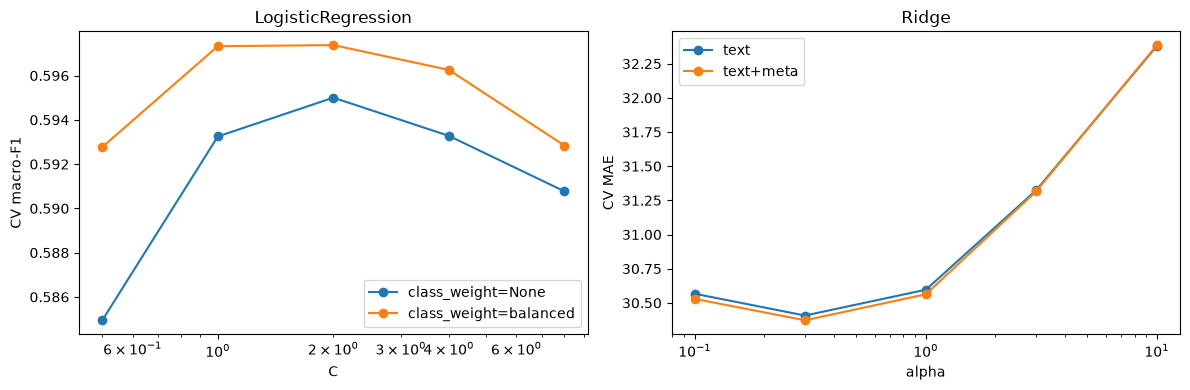

In [12]:
# Визуализация подбора регуляризации
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for cw, g in cv_c.groupby("class_weight"):
    ax[0].plot(g["C"], g["cv_f1"], marker="o", label=f"class_weight={cw}")
for f, g in cv_r.groupby("features"):
    ax[1].plot(g["alpha"], g["cv_mae"], marker="o", label=f)
ax[0].set(xscale="log", xlabel="C", ylabel="CV macro-F1", title="LogisticRegression")
ax[1].set(xscale="log", xlabel="alpha", ylabel="CV MAE", title="Ridge")
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()

### 3.3-3.5 Улучшенный бейзлайн

In [13]:
# Лучшие конфигурации по CV -> обучение на всём train -> тест
best_c = cv_c.loc[cv_c["cv_f1"].idxmax()]
best_r = cv_r.loc[cv_r["cv_mae"].idxmin()]
print(best_c.to_dict(), best_r.to_dict())
cw = None if best_c["class_weight"] == "None" else "balanced"
lr_c2 = LogisticRegression(C=best_c["C"], class_weight=cw, max_iter=2000).fit(B_tr, ya_tr)
res["classification"]["improved"] = clf_metrics(ya_te, lr_c2.predict(B_te))
Xr_tr, Xr_te = (GM_tr, GM_te) if best_r["features"] == "text+meta" else (G_tr, G_te)
lr_r2 = Ridge(best_r["alpha"]).fit(Xr_tr, yf_tr)
res["regression"]["improved"] = reg_metrics(yf_te, lr_r2.predict(Xr_te))
results_table(res)

{'C': 2.0, 'class_weight': 'balanced', 'cv_f1': 0.5973773512307544} {'alpha': 0.3, 'features': 'text+meta', 'cv_mae': 30.37265991340524}


,задача,этап,f1_macro,accuracy,mae,rmse,r2
0,classification,baseline,0.5811,0.5868,NaN,NaN,NaN
1,classification,improved,0.5971,0.6004,NaN,NaN,NaN
2,regression,baseline,NaN,NaN,2334.731,2961.504,-4819.7328
3,regression,improved,NaN,NaN,29.325,37.341,0.2336


In [14]:
# Интерпретация: слова/биграммы с наибольшими весами для отрицательного и положительного классов
names = np.array(vec_a2.get_feature_names_out())
for ci, cname in [(0, "Отрицательный"), (2, "Положительный")]:
    top = np.argsort(lr_c2.coef_[ci])[-15:][::-1]
    print(cname, ":", ", ".join(names[top]))

Отрицательный : не рекомендую, не советую, дроп, скучно, дропнул, разочарование, абсолютно, ужасно, плохо, бред, ни, хуже, шлак, зачем, ничего
Положительный : 10 10, 10 из, очень, просмотреномоя, просмотреномоя оценка, мною просмотреномоя, прекрасно, однозначно, отличная, отлично, рекомендую, просмотру, великолепно, лучших, история


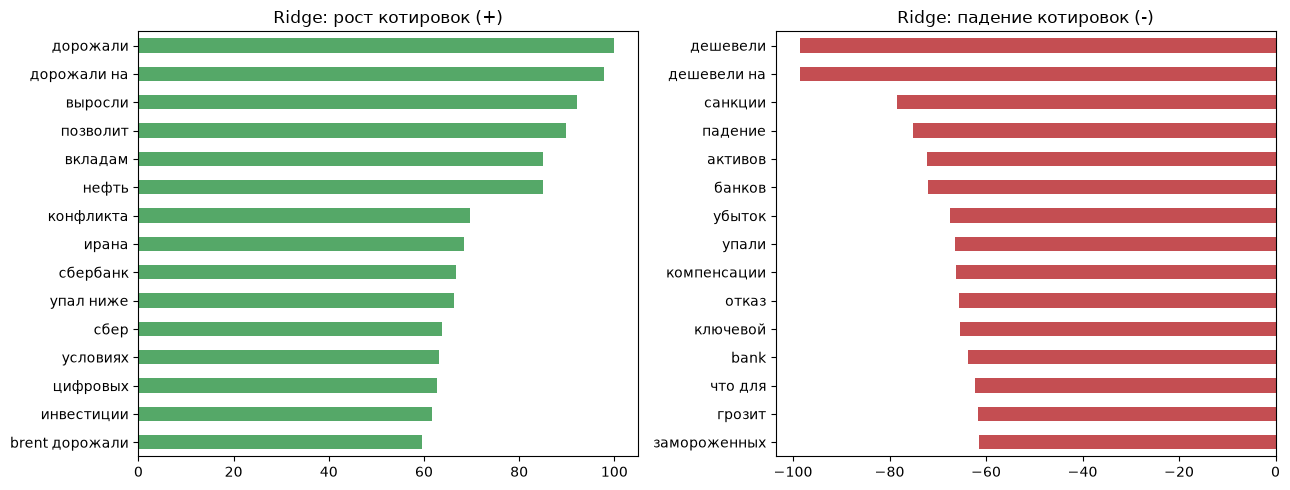

In [15]:
# Важность признаков регрессии: коэффициенты Ridge (признаки TF-IDF одной шкалы, поэтому коэффициенты сравнимы)
names_r = list(vec_f2.get_feature_names_out()) + (FEATURE_NAMES["meta"] if best_r["features"] == "text+meta" else [])
coef = pd.Series(lr_r2.coef_, index=names_r)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
coef.nlargest(15)[::-1].plot.barh(ax=ax[0], title="Ridge: рост котировок (+)", color="#55A868")
coef.nsmallest(15)[::-1].plot.barh(ax=ax[1], title="Ridge: падение котировок (-)", color="#C44E52")
plt.tight_layout(); plt.show()

### 3.7 Выводы по улучшению

- **H1 (биграммы + sublinear tf + min_df) подтверждена:** CV macro-F1 0.580 -> 0.593, CV MAE 30.69 -> 30.60. Биграммы ловят отрицания и устойчивые обороты ("не рекомендую", "не советую", "дешевели на").
- **H2 (регуляризация) подтверждена:** для логрегрессии оптимум C~2 (меньше - недообучение, больше - переобучение). Для регрессии ключевое: `LinearRegression` без регуляризации при 62 676 признаках на 8 268 статьях интерполирует train и **полностью разваливается на тесте** (MAE 2335, R2 -4820). Ridge с alpha=0.3 исправляет это: MAE **29.33**, R2 **0.234**.
- **H3 (балансировка классов) подтверждена:** `class_weight="balanced"` даёт +0.002-0.008 macro-F1 при любом C - модель чаще предсказывает редкий отрицательный класс.
- **H4 (метаданные) подтвердилась слабо:** -0.03 MAE на CV, на грани шума.
- Интерпретация весов правдоподобна: для отрицательных отзывов - "не рекомендую", "дроп", "скучно", "шлак"; для положительных - "10 из 10", "рекомендую", "великолепно". Сильный сигнал дают шаблонные фразы сайта ("просмотрено, моя оценка ..."): часть отзывов явно содержит оценку. В регрессии рост котировок связан со словами "дорожали", "выросли", "нефть", "brent дорожали", падение - с "дешевели", "санкции", "падение", "убыток", "ключевой" (ставкой).
- Итог: macro-F1 **0.581 -> 0.597**; MAE **2335 -> 29.33**.

## 4. Собственная реализация

Обе модели обучаются **ускоренным градиентным спуском Нестерова** с постоянным шагом `1 / L`, где `L` -
константа Липшица градиента, оценённая через наибольшее сингулярное число матрицы признаков (степенной метод).
Работают с разреженными матрицами, свободный член не регуляризуется.

- **Мультиклассовая логистическая регрессия (softmax):**
  `J(W, b) = 1/n * sum(s_i * CE(y_i, softmax(x_i @ W + b))) + 1/(2*C*n) * sum(W**2)`
  - с точностью до множителя совпадает с целевой функцией sklearn; `s_i` - веса объектов (для `class_weight`).
- **Линейная регрессия с L2 (Ridge):**
  `J(w, b) = 1/(2*n) * sum((X @ w + b - y)**2) + alpha/(2*n) * sum(w**2)`; при `alpha = 0` - обычный МНК.

In [16]:
def top_singular(X, iters=30, seed=0):
    """Наибольшее сингулярное число матрицы X степенным методом (для шага градиентного спуска)."""
    v = np.random.default_rng(seed).normal(size=X.shape[1])
    for _ in range(iters):
        v = X.T @ (X @ v); v /= np.linalg.norm(v)
    return np.linalg.norm(X @ v)


def nesterov(grad, x0, lr, n_iter, tol=1e-7):
    """Ускоренный градиентный спуск Нестерова с остановкой по малому изменению параметров."""
    x, y, t = x0.copy(), x0.copy(), 1.0
    for _ in range(n_iter):
        x_new = y - lr * grad(y)
        t_new = (1 + np.sqrt(1 + 4 * t * t)) / 2
        y = x_new + (t - 1) / t_new * (x_new - x)
        if np.linalg.norm(x_new - x) < tol * (1 + np.linalg.norm(x)):
            x = x_new; break
        x, t = x_new, t_new
    return x


class MyLogisticRegression:
    """Softmax-регрессия с L2. Параметры объединены в матрицу (d+1, K): последняя строка - bias."""

    def __init__(self, C=1.0, class_weight=None, n_iter=500):
        self.C, self.class_weight, self.n_iter = C, class_weight, n_iter

    def fit(self, X, y):
        n, d = X.shape
        self.classes_ = np.unique(y)
        K = len(self.classes_)
        Y = (y[:, None] == self.classes_).astype(float)
        # Веса объектов как в sklearn: n / (K * n_class) для balanced
        s = np.ones(n) if self.class_weight is None else (n / (K * Y.sum(0)))[Y.argmax(1)]
        lam = 1.0 / (self.C * n)

        def grad(theta):
            W, b = theta[:-1], theta[-1]
            Z = X @ W + b
            P = np.exp(Z - Z.max(1, keepdims=True)); P /= P.sum(1, keepdims=True)
            R = (P - Y) * s[:, None] / n                    # dJ/dZ
            return np.vstack([X.T @ R + lam * W, R.sum(0)])

        # Гессиан softmax-CE ограничен 1/2 * X^T X -> L <= 0.5 * sigma^2 * max(s) / n + lam
        L = 0.5 * (top_singular(X) ** 2 + n) * s.max() / n + lam
        theta = nesterov(grad, np.zeros((d + 1, K)), 1.0 / L, self.n_iter)
        self.coef_, self.intercept_ = theta[:-1].T, theta[-1]
        return self

    def predict(self, X):
        return self.classes_[(X @ self.coef_.T + self.intercept_).argmax(1)]


class MyLinearRegression:
    """Линейная регрессия с L2 (alpha=0 - МНК) градиентным спуском Нестерова."""

    def __init__(self, alpha=0.0, n_iter=1000):
        self.alpha, self.n_iter = alpha, n_iter

    def fit(self, X, y):
        n, d = X.shape
        self.y_mean = y.mean()
        yc = y - self.y_mean                                # центрирование цели ускоряет сходимость bias

        def grad(theta):
            w, b = theta[:-1], theta[-1]
            r = (X @ w + b - yc) / n
            return np.append(X.T @ r + self.alpha / n * w, r.sum())

        L = (top_singular(X) ** 2 + n + self.alpha) / n
        theta = nesterov(grad, np.zeros(d + 1), 1.0 / L, self.n_iter)
        self.coef_, self.intercept_ = theta[:-1], theta[-1] + self.y_mean
        return self

    def predict(self, X):
        return X @ self.coef_ + self.intercept_

### 4.2-4.3 Собственная реализация с параметрами бейзлайна
TF-IDF по умолчанию; логрегрессия с C=1 без балансировки; линейная регрессия без регуляризации (alpha=0).

In [17]:
# Обучение и оценка собственных моделей в конфигурации бейзлайна
my_c = MyLogisticRegression(C=1.0).fit(A_tr, ya_tr)
res["classification"]["custom"] = clf_metrics(ya_te, my_c.predict(A_te))
my_r = MyLinearRegression(alpha=0.0).fit(F_tr, yf_tr)
res["regression"]["custom"] = reg_metrics(yf_te, my_r.predict(F_te))
# Насколько близки решения логрегрессии к sklearn (доля совпавших предсказаний)
print("совпадение с sklearn LogReg:", (my_c.predict(A_te) == lr_c.predict(A_te)).mean())
results_table({t: {s: d[s] for s in ["baseline", "custom"]} for t, d in res.items()})

совпадение с sklearn LogReg: 0.9737758656013112


,задача,этап,f1_macro,accuracy,mae,rmse,r2
0,classification,baseline,0.5811,0.5868,NaN,NaN,NaN
1,classification,custom,0.5823,0.5881,NaN,NaN,NaN
2,regression,baseline,NaN,NaN,2334.731,2961.504,-4819.7328
3,regression,custom,NaN,NaN,35.311,44.755,-0.1010


### 4.5 Выводы

- **Классификация:** собственная softmax-регрессия (ускоренный градиентный спуск Нестерова) даёт macro-F1 0.582 против 0.581 у sklearn - почти та же модель (небольшие расхождения из-за того, что 500 итераций GD не доводят оптимизацию до той же точности, что L-BFGS).
- **Регрессия:** собственный МНК без регуляризации даёт MAE 35.3 вместо 2335 у sklearn. Это не "лучшая реализация", а эффект **ранней остановки**: градиентный спуск, начатый из нуля и остановленный через 1000 итераций, не успевает дойти до интерполирующего решения и действует как неявная регуляризация. Однако R2 -0.10 - модель всё равно хуже константы, т.е. без явной регуляризации линейная регрессия здесь непригодна.

### 4.6-4.8 Собственная реализация + техники улучшенного бейзлайна
Биграммы + sublinear tf, подобранная регуляризация, балансировка классов, метаданные для регрессии.

In [18]:
# Собственные модели с лучшими найденными гиперпараметрами и признаками
my_c2 = MyLogisticRegression(C=best_c["C"], class_weight=cw).fit(B_tr, ya_tr)
res["classification"]["custom_improved"] = clf_metrics(ya_te, my_c2.predict(B_te))
my_r2 = MyLinearRegression(alpha=best_r["alpha"]).fit(Xr_tr, yf_tr)
res["regression"]["custom_improved"] = reg_metrics(yf_te, my_r2.predict(Xr_te))
results_table({t: {s: d[s] for s in ["improved", "custom_improved"]} for t, d in res.items()})

,задача,этап,f1_macro,accuracy,mae,rmse,r2
0,classification,improved,0.5971,0.6004,NaN,NaN,NaN
1,classification,custom_improved,0.5958,0.5995,NaN,NaN,NaN
2,regression,improved,NaN,NaN,29.325,37.341,0.2336
3,regression,custom_improved,NaN,NaN,29.355,37.359,0.2328


### 4.10 Выводы

С техниками улучшенного бейзлайна (биграммы, sublinear tf, C=2 + balanced, Ridge alpha=0.3 + метаданные) собственные модели практически совпали со sklearn: macro-F1 **0.596** против 0.597, MAE **29.36** против 29.33. Регуляризованные задачи хорошо обусловлены, и градиентный спуск сходится к тому же решению.

## Сравнение всех этапов

Сводная таблица метрик на тестовой выборке: бейзлайн (п.2), улучшенный бейзлайн (п.3), собственная реализация (п.4) и собственная реализация с техниками улучшенного бейзлайна.

In [19]:
# Таблица метрик по всем этапам и сохранение в labs/results/LR2.json для итогового ноутбука
table = results_table(res)
save_results("LR2", res)
table

,задача,этап,f1_macro,accuracy,mae,rmse,r2
0,classification,baseline,0.5811,0.5868,NaN,NaN,NaN
1,classification,improved,0.5971,0.6004,NaN,NaN,NaN
2,classification,custom,0.5823,0.5881,NaN,NaN,NaN
3,classification,custom_improved,0.5958,0.5995,NaN,NaN,NaN
4,regression,baseline,NaN,NaN,2334.731,2961.504,-4819.7328
5,regression,improved,NaN,NaN,29.325,37.341,0.2336
6,regression,custom,NaN,NaN,35.311,44.755,-0.1010
7,regression,custom_improved,NaN,NaN,29.355,37.359,0.2328


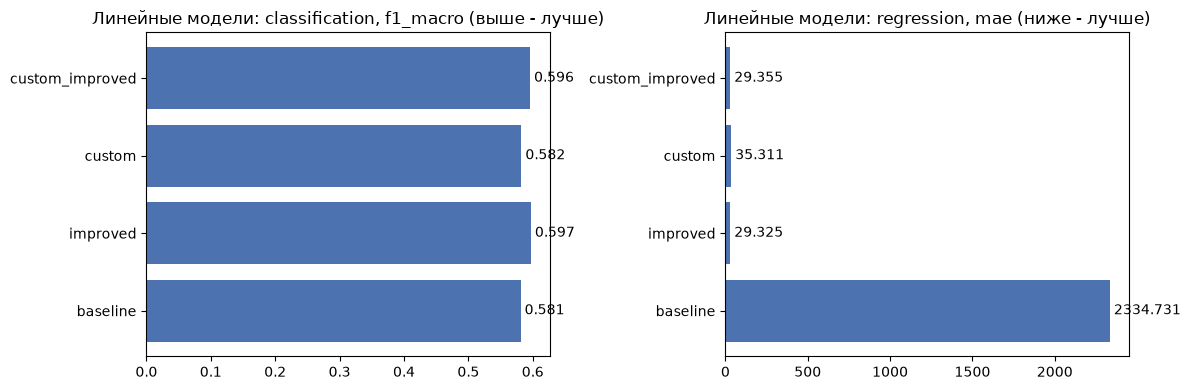

In [20]:
# Визуальное сравнение основной метрики каждой задачи по этапам
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, (task, metric) in zip(ax, [("classification", "f1_macro"), ("regression", "mae")]):
    t = table[table["задача"] == task]
    a.barh(t["этап"], t[metric], color="#4C72B0")
    a.set_title(f"Линейные модели: {task}, {metric}" + (" (выше - лучше)" if metric == "f1_macro" else " (ниже - лучше)"))
    for i, v in enumerate(t[metric]):
        a.text(v, i, f" {v:.3f}", va="center")
plt.tight_layout(); plt.show()

## Выводы

1. Линейные модели на TF-IDF с биграммами - **лучший алгоритм в обеих задачах** (macro-F1 0.597, MAE 29.33, R2 0.234): для текстов с сотнями тысяч разреженных признаков линейная граница почти оптимальна.
2. Для регрессии регуляризация обязательна: без неё МНК при p >> n переобучается катастрофически.
3. Модели интерпретируемы: веса слов прямо показывают маркеры тональности и "рыночные" слова.
4. Собственные реализации на градиентном спуске совпадают со sklearn с точностью до 0.002 F1 / 0.03 MAE.